# DSCI 552 - Homework 7

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## AI Use Disclosure

I used GitHub Copilot in VS Code to help with this homework.

- **Code:** Copilot help me in suggesting code and helped revise code for loading and splitting the data, training Gaussian and L1 SVMs, choosing settings with 10-fold cross-validation, using class weights, and calculating evaluation scores. It also helped make suggestions on the K-means clustering, CH score selection, and 50-run simulation code.

- **Debugging:** Copilot helped identify and fix issues with exact-match calculations, indentation, cluster membership comparisons, and a missing NumPy import.

- **Written answers:** Copilot explained the methods and explained the simplified answers using my notebook results.

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### 1(a) - Download the Anuran Calls (MFCCs) Data Set from: https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29. Choose 70% of the data randomly as the training set.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

csv_path = Path("../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv")
df = pd.read_csv(csv_path)

label_columns = ["Family", "Genus", "Species"]
feature_columns = [column for column in df.columns if column.startswith("MFCCs")]


X = df[feature_columns]
y = df[label_columns]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.70,
    random_state=42
)

print("Full Data: ", df.shape)
print("Training Features: ", X_train.shape)
print("Test Features: ", X_test.shape)

Full Data:  (7195, 26)
Training Features:  (5036, 22)
Test Features:  (2159, 22)


### 1(b) - Each instance has three labels: Families, Genus, and Species. Each of the labels has multiple classes. We wish to solve a multi-class and multi-label problem. One of the most important approaches to multi-label classification is to train a classifier for each label (binary relevance). We first try this approach:

#### 1(b)(i) -  Research exact match and hamming score/ loss methods for evaluating multi-label classification and use them in evaluating the classifiers in this problem.

**Answer:** Exact match counts an observation as correct only when Family, Genus and Species are all predicted correctly. Hamming loss counts the fraction of individul labels that are wrong. Hamming score counts the fraction that are right, so it equals 1 minus Hamming loss.

- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html 
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html

#### 1(b)(ii) - Train a SVM for each of the labels, using Gaussian kernels and one versus all classifiers. Determine the weight of the SVM penalty and the width of the Gaussian Kernel using 10 fold cross validation.1 You are welcome to try to solve the problem with both standardized 2 and raw attributes and report the results.

In [2]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

parameter_grid = {
    "classifier__estimator__C": [0.1, 1, 10, 100],
    "classifier__estimator__gamma": [0.001, 0.01, 0.1, 1, 10],
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

models = {}
predictions = pd.DataFrame(index=y_test.index)

for label in label_columns:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", OneVsRestClassifier(SVC(kernel="rbf"))),
    ])

    search = GridSearchCV(
        model,
        parameter_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train[label])

    models[label] = search.best_estimator_
    predictions[label] = search.best_estimator_.predict(X_test)

    best_gamma = search.best_params_["classifier__estimator__gamma"]
    sigma = (1 / (2 * best_gamma)) ** 0.5

    print(f"\n{label}")
    print("Best C:", search.best_params_["classifier__estimator__C"])
    print("Best gamma:", best_gamma)
    print("Equivalent Gaussian width (sigma):", round(sigma, 4))
    print("Best 10-fold CV accuracy:", round(search.best_score_, 4))
    print("Test accuracy:", round(accuracy_score(y_test[label], predictions[label]), 4))

exact_match = (
    y_test.to_numpy() == predictions.to_numpy()
).all(axis=1).mean()

hamming_loss = (
    y_test.to_numpy() != predictions.to_numpy()
).mean()

print("\nCombined test results")
print("Exact match:", round(exact_match, 4))
print("Hamming score:", round(1 - hamming_loss, 4))
print("Hamming loss:", round(hamming_loss, 4))


Family
Best C: 10
Best gamma: 0.1
Equivalent Gaussian width (sigma): 2.2361
Best 10-fold CV accuracy: 0.9905
Test accuracy: 0.9935

Genus
Best C: 10
Best gamma: 0.1
Equivalent Gaussian width (sigma): 2.2361
Best 10-fold CV accuracy: 0.9891
Test accuracy: 0.9884

Species
Best C: 10
Best gamma: 0.1
Equivalent Gaussian width (sigma): 2.2361
Best 10-fold CV accuracy: 0.9889
Test accuracy: 0.988

Combined test results
Exact match: 0.9866
Hamming score: 0.99
Hamming loss: 0.01


**Answer**: I trained one SVM for each label (Family, Genus and Species). I standarized the features and used 10-fold cross-validation to choose the best settings. All threemodels chose C=10 and gamma=.1.

On the test data the exact maatch was .9866 the Hamming score was .9900 and the Hamming loss was .01. This means all three labels were correct for about 98.66% of the test observations, and about 1% of the indivdual labels were wrong.

#### 1(b)(iii) - Repeat 1(b)ii with L1-penalized SVMs.3 Remember to standardize4 the attributes. Determine the weight of the SVM penalty using 10 fold cross validation.

In [3]:
from sklearn.svm import SVC, LinearSVC

c_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)

for label in label_columns:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=200000,
            random_state=42
        )),
    ])

    search = GridSearchCV(
        model,
        {"svm__C": c_values},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_
    l1_predictions[label] = search.best_estimator_.predict(X_test)

    print(f"\n{label}")
    print("Best C:", search.best_params_["svm__C"])
    print("Best 10-fold CV Accuracy:", round(search.best_score_, 4))
    print(
        "Test Accuracy:", 
        round(accuracy_score(y_test[label], l1_predictions[label]), 4)
    )

l1_exact_match = (
    y_test.to_numpy() == l1_predictions.to_numpy()
).all(axis=1).mean()

l1_hamming_loss = (
    y_test.to_numpy() != l1_predictions.to_numpy()
).mean()

print("\nCombined Test Results")
print("Exact Match:", round(l1_exact_match, 4))
print("Hamming Loss:", round(l1_hamming_loss, 4))
print("Hamming Score:", round(1 - l1_hamming_loss, 4))


Family
Best C: 10
Best 10-fold CV Accuracy: 0.9412
Test Accuracy: 0.9282

Genus
Best C: 1000
Best 10-fold CV Accuracy: 0.9517
Test Accuracy: 0.9416

Species
Best C: 10
Best 10-fold CV Accuracy: 0.9607
Test Accuracy: 0.9592

Combined Test Results
Exact Match: 0.9125
Hamming Loss: 0.057
Hamming Score: 0.943


#### 1(b)(i) -  Research exact match and hamming score/ loss methods for evaluating multi-label classification and use them in evaluating the classifiers in this problem.

**Answer:** I trained one L1 SVM for each label. The best C was 10 for Family, 1000 for Genus and 10 for Species.

On the test data the exact match was .9125, the Hamming score was .9430, and the hamming loss was .0570.

#### 1(b)(iv) - Repeat 1(b)(iii) by using SMOTE or any other method you know to remedy class imbalance. Report your conclusions about the classifiers you trained.

In [4]:
from sklearn.metrics import balanced_accuracy_score

balanced_l1_models = {}
balanced_l1_predictions = pd.DataFrame(index=y_test.index)

for label in label_columns:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=200000,
            random_state=42,
            class_weight="balanced"
        ))
    ])

    search = GridSearchCV(
        model,
        {"svm__C": c_values},
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train[label])

    balanced_l1_models[label] = search.best_estimator_
    balanced_l1_predictions[label] = search.best_estimator_.predict(X_test)

    print(f"\n{label}")
    print("Best C:", search.best_params_["svm__C"])
    print("CV balanced accuracy:", round(search.best_score_, 4))
    print(
        "Test balanced accuracy:",
        round(balanced_accuracy_score(y_test[label], balanced_l1_predictions[label]), 4)
    )
    print(
        "Test accuracy:",
        round(accuracy_score(y_test[label], balanced_l1_predictions[label]), 4)
    )

balanced_exact_match = (
    y_test.to_numpy() == balanced_l1_predictions.to_numpy()
).all(axis=1).mean()

balanced_hamming_loss = (
    y_test.to_numpy() != balanced_l1_predictions.to_numpy()
).mean()

print("Combined Test Results")
print("Exact Match:", round(balanced_exact_match, 4))
print("Hamming Loss:", round(balanced_hamming_loss, 4))
print("Hamming Score:", round(1 - balanced_hamming_loss, 4))


Family
Best C: 100
CV balanced accuracy: 0.9141
Test balanced accuracy: 0.9039
Test accuracy: 0.9217

Genus
Best C: 1
CV balanced accuracy: 0.8887
Test balanced accuracy: 0.8981
Test accuracy: 0.9412


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Species
Best C: 1000
CV balanced accuracy: 0.9076
Test balanced accuracy: 0.9105
Test accuracy: 0.9597
Combined Test Results
Exact Match: 0.9064
Hamming Loss: 0.0591
Hamming Score: 0.9409


**Answer:** I used class weights to give more attention to the less common classes. The best C values were 100 for family, 1 for Genus and 1000 for Species.

on the test data the exct match was .9064, the hamming score was .9409, and the hamming loss was .0591. This was slightly worse than the L1 SVM without class weights which had an exact match of about .9125.

## 2 K-Means Clustering on a Multi-Class and Multi-Label Data Set 

**Monte-Carlo Simulation**: Perform the following procedures 50 times, and report the average and standard deviation of the 50 Hamming Distances that you calculate.

### 2(a) Use k-means clustering on the whole Anuran Calls (MFCCs) Data Set (do not split the data into train and test, as we are not performing supervised learning in this exercise). Choose k ∈ {1, 2, . . . , 50} automatically based on one of the methods provided in the slides (CH or Gap Statistics or scree plots or Silhouettes) or any other method you know

Best k: 2
Best CH Score: 3680.7413


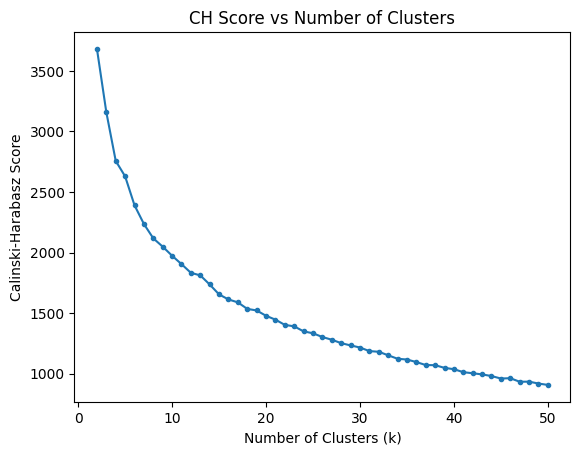

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

feature_columns = [c for c in df.columns if c.startswith("MFCCs")]
label_columns = ["Family", "Genus", "Species"]

x_all = df[feature_columns]
y_all = df[label_columns]
ch_scores = []

for k in range(2, 51):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_ids = model.fit_predict(x_all)
    score = calinski_harabasz_score(x_all, cluster_ids)
    ch_scores.append((k, score))

best_k, best_ch_score = max(ch_scores, key=lambda results: results[1])

print("Best k:", best_k)
print("Best CH Score:", round(best_ch_score, 4))

ks, scores = zip(*ch_scores)
plt.plot(ks, scores, marker='.')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("CH Score vs Number of Clusters")
plt.show()

### 2(b) In each cluster, determine which family is the majority by reading the true labels. Repeat for genus and species.

In [6]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
clusters = kmeans.fit_predict(x_all)
majority_rows = []

for cluster_id in sorted(set(clusters)):
    members = clusters == cluster_id
    row = {
        "Cluster": cluster_id,
        "Number of Observations": int(members.sum())
    }

    for label in label_columns:
        row[label] = y_all.loc[members, label].mode().iloc[0]
    
    majority_rows.append(row)

majority_labels = pd.DataFrame(majority_rows)
display(majority_labels)

,Cluster,Number of Observations,Family,Genus,Species
0,0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


### 2(c) Now for each cluster you have a majority label triplet (family, genus, species). Calculate the average Hamming distance, Hamming score, and Hamming loss between the true labels and the labels assigned by clusters.

In [7]:
import numpy as np

simulation_results = []

for seed in range(50):

    best_score = -np.inf
    best_clusters = None
    selected_k = None

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=seed
        )
        cluster_ids = model.fit_predict(x_all)
        ch_score = calinski_harabasz_score(x_all, cluster_ids)

        if ch_score > best_score:
            best_score = ch_score
            best_clusters = cluster_ids
            selected_k = k

    predicted_labels = pd.DataFrame(
        index=y_all.index,
        columns=label_columns,
        dtype=object
    )

    for cluster_id in sorted(set(best_clusters)):
        members = best_clusters == cluster_id

        for label in label_columns:
            majority_label = y_all.loc[members, label].mode().iloc[0]
            predicted_labels.loc[members, label] = majority_label

    mismatches = y_all.to_numpy() != predicted_labels.to_numpy()
    loss = mismatches.mean()

    simulation_results.append({
        "Run": seed + 1,
        "Selected k": selected_k,
        "Hamming distance": mismatches.sum(axis=1).mean(),
        "Hamming score": 1 - loss,
        "Hamming loss": loss
    })

    print(f"Finished run {seed + 1}/50: k = {selected_k}")

simulation_results = pd.DataFrame(simulation_results)

mean_distance = simulation_results["Hamming distance"].mean()
std_distance = simulation_results["Hamming distance"].std(ddof=1)
mean_score = simulation_results["Hamming score"].mean()
mean_loss = simulation_results["Hamming loss"].mean()

print("\nSelected cluster counts:")
print(simulation_results["Selected k"].value_counts().sort_index())

print("\nMean Hamming Distance:", round(mean_distance, 4))
print("Hamming Distance Standard Deviation:", round(std_distance, 4))
print("Mean Hamming Score:", round(mean_score, 4))
print("Mean Hamming Loss:", round(mean_loss, 4))

Finished run 1/50: k = 2
Finished run 2/50: k = 2
Finished run 3/50: k = 2
Finished run 4/50: k = 2
Finished run 5/50: k = 2
Finished run 6/50: k = 2
Finished run 7/50: k = 2
Finished run 8/50: k = 2
Finished run 9/50: k = 2
Finished run 10/50: k = 2
Finished run 11/50: k = 2
Finished run 12/50: k = 2
Finished run 13/50: k = 2
Finished run 14/50: k = 2
Finished run 15/50: k = 2
Finished run 16/50: k = 2
Finished run 17/50: k = 2
Finished run 18/50: k = 2
Finished run 19/50: k = 2
Finished run 20/50: k = 2
Finished run 21/50: k = 2
Finished run 22/50: k = 2
Finished run 23/50: k = 2
Finished run 24/50: k = 2
Finished run 25/50: k = 2
Finished run 26/50: k = 2
Finished run 27/50: k = 2
Finished run 28/50: k = 2
Finished run 29/50: k = 2
Finished run 30/50: k = 2
Finished run 31/50: k = 2
Finished run 32/50: k = 2
Finished run 33/50: k = 2
Finished run 34/50: k = 2
Finished run 35/50: k = 2
Finished run 36/50: k = 2
Finished run 37/50: k = 2
Finished run 38/50: k = 2
Finished run 39/50: k

**Answer:** The CH score picked 2 clusters. I ran k-means 50 times and gave each observation the most common labels in its cluster.

The average Hamming distance was .8956 with a standard deviation of .00. The Hamming score was .7015 and the Hamming loss was .2985. This means about 70.15% of the individual labels were correct and 29.85% were wrong.

## 3. ISLR 12.6.2

Suppose that we have four observations, for which we compute a dissimilarity matrix, given by:

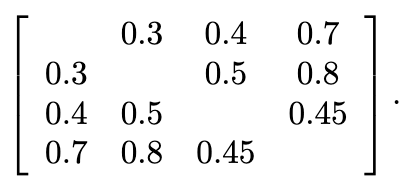

For instance, the dissimilarity between the first and second observations is 0.3, and the dissimilarity between the second and fourth observations is 0.8.

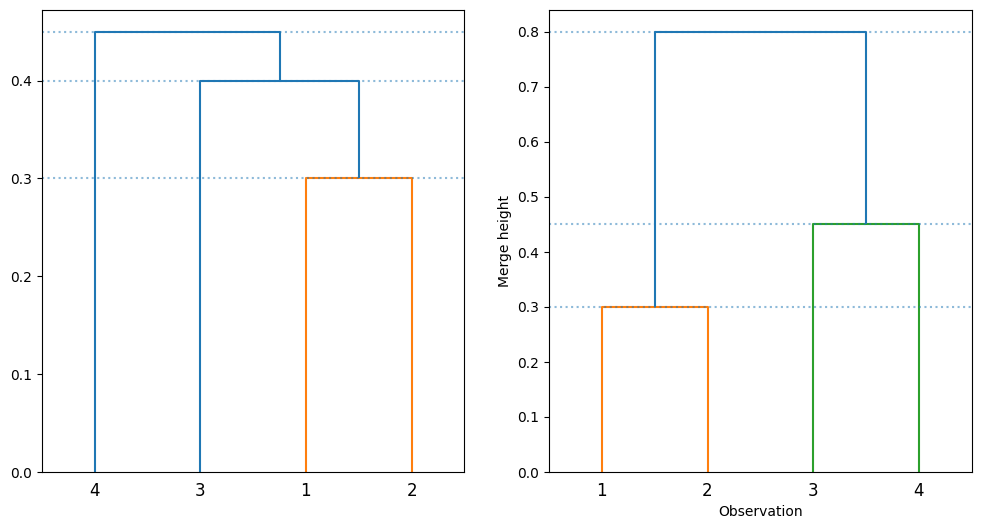

In [8]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

distances = [0.3, 0.4, 0.7, 0.5, 0.8, 0.45]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, method in zip(axes, ["single", "complete"]):
    merges = linkage(distances, method=method)

    dendrogram(
        merges,
        ax=ax,
        labels=["1", "2", "3", "4"]
    )

    for height in merges[:, 2]:
        ax.axhline(height, linestyle=':', alpha=0.5)

ax.set_xlabel("Observation")
ax.set_ylabel("Merge height")

plt.show()

### 3(a) On the basis of this dissimilarity matrix, sketch the dendrogram that results from hierarchically clustering these four observations using complete linkage. Be sure to indicate on the plot the height at which each fusion occurs, as well as the observations corresponding to each leaf in the dendrogram.

**Answer**: 
- Observations 1 and 2 join first at heigh 0.30
- Observations 3 and 4 jion at height .45
- The two groups then join at heigh .80 which is the largest distance between them.

### 3(b) Repeat (a), this time using single linkage clustering.

**Answer:** 
- Observations 1 and 2 join first at height 0.30
- Observation 3 joins that group at height 0.40, because its closest distance to the group is 0.40. 
- Observation 4 joins at height 0.45, because its closest distance to the group is 0.45.

### 3(c) Suppose that we cut the dendrogram obtained in (a) such that two clusters result. Which observations are in each cluster?

**Answer:** Cutting the complete-linkage tree into two clusters gives:
- Cluster 1: observations 1 and 2
- Cluster 2: observations 3 and 4

### 3(d) Suppose that we cut the dendrogram obtained in (b) such that two clusters result. Which observations are in each cluster?

**Answer: ** Cutting the single-linkage tree into two clusters gives:
- Cluster 1: observations 1, 2, and 3
- Cluster 2: observation 4

### 3(e) It is mentioned in this chapter that at each fusion in the den- drogram, the position of the two clusters being fused can be swapped without changing the meaning of the dendrogram. Draw a dendrogram that is equivalent to the dendrogram in (a), for which two or more of the leaves are repositioned, but for which the meaning of the dendrogram is the same.

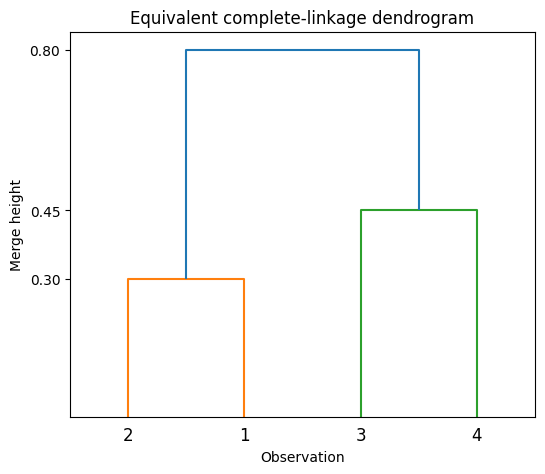

In [9]:
complete_merges = linkage(distances, method="complete")

complete_merges[0, 0], complete_merges[0, 1] = (
    complete_merges[0, 1], 
    complete_merges[0, 0]
)

plt.figure(figsize=(6, 5))
dendrogram(complete_merges, labels=["1", "2", "3", "4"])
plt.yticks([0.30, 0.45, 0.80])
plt.xlabel("Observation")
plt.ylabel("Merge height")
plt.title("Equivalent complete-linkage dendrogram")
plt.show()

**Answer:** I swapped the position of observations 1 and 2. They still join at heigh .30, observations 3 and 4 still jion at .45, and the two groups still join at .80. Only the order of the leaves changed so the dendogram means the same thing.